# Part 4.E — CLIP zero-shot classification

CLIP aligns images and text in one embedding space, so it can classify without
training a target-specific head. This notebook evaluates:

1. **zero-shot CLIP** with several prompt banks (single prompt, template
   ensembles, synonyms, short descriptions);
2. **prompt sensitivity** — one template at a time;
3. **CLIP + linear SVM** on the same frozen image embeddings, as the supervised
   counterpart.

Protocol: prompts are selected on the shared **internal validation** split
(`results/part4_internal_val_names.csv`), never on test. The `*_val` split is
scored once for the selected bank. Three views are reported because the splits
contain `background`:

* 5-way accuracy on object images only (the five target classes);
* 6-way accuracy/confusion including an explicit background prompt;
* one-vs-rest AP/mAP with background as negatives (comparable to Stages A–D).

The CLIP image cache is written to `data/deep_features/clip_vit_b_32/`, and the
selected text bank to `selected_text_bank.npz`, so Stage F can reuse both.

In [11]:
import json
import os
import sys
import time
from pathlib import Path


def _find_code_dir():
    '''Locate the directory containing src/ (works from code/ or the repo root).'''
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "code"):
            if (candidate / "src" / "deep_models.py").exists():
                return candidate
    raise FileNotFoundError(
        "Could not find src/deep_models.py. Open the notebook from code/ or the repo root."
    )


CODE_DIR = _find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

import clip
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
)

from src.deep_eval import (
    BACKGROUND,
    CATEGORIES,
    DEFAULT_C_GRID,
    binary_subset,
    evaluate_binary,
    evaluate_multiclass,
    l2norm,
    save_results,
)
from src.deep_features import (
    FEATURE_ROOT,
    extract_clip_features,
    load_feature_cache,
    save_feature_cache,
)
from src.deep_models import getModel
from src.utils import loadSamplesTable

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --------------------------- experiment configuration -----------------------
TAG = "clip_vit_b_32"
KEY = "features_clip"
BATCH_SIZE = 32
SEED = 0
VAL_FRACTION = 0.2
C_GRID = (0.1, 1.0, 10.0, 100.0)          # CLIP embeddings are already compact
MAX_ITER = 10000

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)

# --------------------------- prompt definitions -----------------------------
TEMPLATES = (
    "a photo of a {}",
    "a photograph of a {}",
    "a picture of a {}",
    "a close-up photo of a {}",
    "a cropped photo of a {}",
    "a photo of the {}",
    "a photo of a {} in the wild",
)
SYNONYMS = {
    "aeroplane": ("aeroplane", "airplane", "plane"),
    "car": ("car", "automobile"),
    "horse": ("horse",),
    "motorbike": ("motorbike", "motorcycle"),
    "person": ("person", "human being"),
}
DESCRIPTIVE = {
    "aeroplane": "a photo of an aeroplane flying in the sky",
    "car": "a photo of a car on a road",
    "horse": "a photo of a horse standing or running",
    "motorbike": "a photo of a motorbike with two wheels",
    "person": "a photo of a person",
}
BACKGROUND_PROMPTS = (
    "a photo of a background scene",
    "a photo of an empty scene",
    "a photo with no object",
    "a photo of scenery without an object",
)

PROMPT_SETS = {
    "label_only": {cat: [cat] for cat in CATEGORIES},
    "single": {cat: [f"a photo of a {cat}"] for cat in CATEGORIES},
    "templates": {cat: [t.format(cat) for t in TEMPLATES] for cat in CATEGORIES},
    "templates_synonyms": {
        cat: [t.format(s) for s in SYNONYMS[cat] for t in TEMPLATES]
        for cat in CATEGORIES
    },
    "descriptive": {cat: [DESCRIPTIVE[cat]] for cat in CATEGORIES},
}
print("Prompt sets:", list(PROMPT_SETS))

Device: cpu
Prompt sets: ['label_only', 'single', 'templates', 'templates_synonyms', 'descriptive']


## E.1 — Load CLIP and extract image embeddings

One pass over train and test, cached in the standard feature layout. The
official CLIP preprocessing is used (Resize 224 bicubic, CenterCrop 224,
CLIP mean/std).

In [12]:
t0 = time.perf_counter()
model, preprocess = getModel("clip_vit_b_32", device)
model.eval()
print(f"CLIP ViT-B/32 loaded in {time.perf_counter() - t0:.2f}s on {device}")
print("Preprocessing:", preprocess)


def get_clip_split(subset, force=False):
    '''Return (features, names, categories) with disk caching.'''
    cache = FEATURE_ROOT / TAG / f"{subset}.npz"
    if cache.exists() and not force:
        return load_feature_cache(TAG, subset, KEY)
    df = loadSamplesTable("data/splits", "data/images", subset=subset, per_class=-1)
    print(f"[extract] {subset}: {len(df)} images")
    t0 = time.perf_counter()
    features = extract_clip_features(model, preprocess, df, device, BATCH_SIZE)
    seconds = time.perf_counter() - t0
    path = save_feature_cache(TAG, subset, {"clip": features}, df)
    print(f"  -> {features.shape} in {seconds:.1f}s "
          f"({1000 * seconds / max(len(df), 1):.1f} ms/img), saved to {path}")
    return features, df.filename.to_numpy().astype(str), df.category.to_numpy().astype(str)


train_features, train_names, train_categories = get_clip_split("train")
test_features, test_names, test_categories = get_clip_split("val")
assert train_features.shape[1] == test_features.shape[1] == 512

train_l2, test_l2 = l2norm(train_features), l2norm(test_features)
print("Train:", train_features.shape, "| Test:", test_features.shape)

CLIP ViT-B/32 loaded in 3.03s on cpu
Preprocessing: Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x000001E89D8DD1C0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Train: (2791, 512) | Test: (2796, 512)


In [13]:
val_path = RESULTS_DIR / "part4_internal_val_names.csv"
if not val_path.exists():
    raise FileNotFoundError(
        f"{val_path} is missing. Run `3_frozen_cnn.ipynb` or `4_dinov2.ipynb` first."
    )
val_names = pd.read_csv(val_path, dtype={"file_name": str})["file_name"].to_numpy()
is_val = np.isin(train_names, val_names)
assert is_val.any(), "the shared split does not match the CLIP cache"
assert not np.isin(test_names, val_names).any(), "internal-val and test overlap"

X_val, y_val = train_l2[is_val], train_categories[is_val]
print(f"internal validation: {len(y_val)} images")
print(pd.Series(y_val).value_counts())

internal validation: 665 images
person        252
background    204
car           106
horse          40
motorbike      40
aeroplane      23
Name: count, dtype: int64


## E.2 — Prompt banks

Each class prompt bank is encoded, L2-normalised, averaged and re-normalised.
The background bank is held fixed across conditions so the 6-way comparison is
fair. Averaging **normalised** embeddings avoids letting one long template
dominate by norm.

In [14]:
def encode_texts(texts):
    '''Return L2-normalised CLIP text embeddings for a list of prompts.'''
    tokens = clip.tokenize(list(texts), truncate=True).to(device)
    with torch.inference_mode():
        embeddings = model.encode_text(tokens).float()
    return embeddings / embeddings.norm(dim=-1, keepdim=True)


def build_bank(prompt_map):
    '''Return (6, 512) bank [aeroplane, car, horse, motorbike, person, background].'''
    vectors = [encode_texts(prompt_map[cat]).mean(dim=0, keepdim=True)
               for cat in CATEGORIES]
    vectors.append(encode_texts(BACKGROUND_PROMPTS).mean(dim=0, keepdim=True))
    bank = torch.cat(vectors, dim=0)
    bank = bank / bank.norm(dim=-1, keepdim=True)
    labels = list(CATEGORIES) + [BACKGROUND]
    return bank.cpu().numpy(), labels


def evaluate_bank(bank, X, categories):
    '''Compute 5-way, 6-way and one-vs-rest metrics for one prompt bank.'''
    scores = X @ bank.T                        # (N, 6)
    labels6 = list(CATEGORIES) + [BACKGROUND]

    # 5-way: object images only
    obj = np.isin(categories, CATEGORIES)
    pred5 = scores[obj][:, :5].argmax(axis=1)
    y5 = categories[obj]
    acc5 = accuracy_score(y5, np.asarray(CATEGORIES)[pred5])
    f1_5 = f1_score(y5, np.asarray(CATEGORIES)[pred5], average="macro")

    # 6-way: objects + background
    pred6 = scores.argmax(axis=1)
    pred6_labels = np.asarray(labels6)[pred6]
    acc6 = accuracy_score(categories, pred6_labels)
    f1_6 = f1_score(categories, pred6_labels, labels=labels6, average="macro")

    # one-vs-rest AP, background as the only negatives
    aps = []
    for i, cat in enumerate(CATEGORIES):
        mask = (categories == cat) | (categories == BACKGROUND)
        y = (categories[mask] == cat).astype(int)
        aps.append(float(average_precision_score(y, scores[mask, i])))

    return dict(acc5=float(acc5), macro_f1_5=float(f1_5),
                acc6=float(acc6), macro_f1_6=float(f1_6),
                mAP=float(np.mean(aps)), **{f"AP_{c}": a for c, a in zip(CATEGORIES, aps)}), scores


# sanity check on one bank
bank, bank_labels = build_bank(PROMPT_SETS["single"])
print("bank:", bank.shape, bank_labels)
print("norm:", np.linalg.norm(bank, axis=1).round(4))

bank: (6, 512) ['aeroplane', 'car', 'horse', 'motorbike', 'person', 'background']
norm: [1. 1. 1. 1. 1. 1.]


## E.3 — Select the prompt bank on internal validation

The selection criterion is **validation mAP** (one-vs-rest AP, the same metric as
Stages A–D). Test metrics for every bank are shown for transparency, but only
the validation winner is used as the notebook’s CLIP configuration.

In [15]:
rows = []
for name, prompt_map in PROMPT_SETS.items():
    bank, _ = build_bank(prompt_map)
    val_metrics, _ = evaluate_bank(bank, X_val, y_val)
    test_metrics, _ = evaluate_bank(bank, test_l2, test_categories)
    rows.append(dict(prompt_set=name,
                     **{f"val_{k}": v for k, v in val_metrics.items()},
                     **{f"test_{k}": v for k, v in test_metrics.items()}))
    print(f"{name:<20s} val mAP={val_metrics['mAP']:.4f}  "
          f"val acc5={val_metrics['acc5']:.4f}  test mAP={test_metrics['mAP']:.4f}")

prompt_df = pd.DataFrame(rows)
best_row = prompt_df.loc[prompt_df.val_mAP.idxmax()]
BEST_PROMPT_SET = str(best_row.prompt_set)
print(f"\nSelected on validation mAP: {BEST_PROMPT_SET}")
save_results(prompt_df, RESULTS_DIR / "part4e_prompt_sets.csv")

best_bank, bank_labels = build_bank(PROMPT_SETS[BEST_PROMPT_SET])
selected_val, _ = evaluate_bank(best_bank, X_val, y_val)
selected_test, selected_scores = evaluate_bank(best_bank, test_l2, test_categories)

np.savez_compressed(
    FEATURE_ROOT / TAG / "selected_text_bank.npz",
    embeddings=best_bank.astype(np.float32),
    categories=np.asarray(bank_labels),
    prompt_set=np.asarray([BEST_PROMPT_SET]),
)
(Path(RESULTS_DIR) / "part4e_selected_prompts.json").write_text(json.dumps(
    {"prompt_set": BEST_PROMPT_SET,
     "prompts": {cat: PROMPT_SETS[BEST_PROMPT_SET][cat] for cat in CATEGORIES},
     "background_prompts": list(BACKGROUND_PROMPTS)},
    indent=2,
))
display(prompt_df.round(4).reset_index(drop=True))
print("\nSelected bank — validation:")
display(pd.DataFrame([selected_val]).round(4))
print("Selected bank — test:")
display(pd.DataFrame([selected_test]).round(4))

label_only           val mAP=0.8643  val acc5=0.5900  test mAP=0.8401
single               val mAP=0.8489  val acc5=0.6616  test mAP=0.8368
templates            val mAP=0.8273  val acc5=0.6529  test mAP=0.8255
templates_synonyms   val mAP=0.8217  val acc5=0.6638  test mAP=0.8187
descriptive          val mAP=0.8028  val acc5=0.6746  test mAP=0.7867

Selected on validation mAP: label_only


,prompt_set,val_acc5,val_macro_f1_5,val_acc6,val_macro_f1_6,val_mAP,val_AP_aeroplane,val_AP_car,val_AP_horse,val_AP_motorbike,...,test_acc5,test_macro_f1_5,test_acc6,test_macro_f1_6,test_mAP,test_AP_aeroplane,test_AP_car,test_AP_horse,test_AP_motorbike,test_AP_person
0,label_only,0.5900,0.5931,0.5173,0.5307,0.8643,0.9671,0.8722,0.8856,0.9782,...,0.6236,0.6278,0.5165,0.5250,0.8401,0.9487,0.8648,0.8991,0.9434,0.5445
1,single,0.6616,0.6769,0.5669,0.6066,0.8489,0.9615,0.8799,0.7832,0.9854,...,0.7155,0.7170,0.5694,0.6066,0.8368,0.9827,0.8682,0.8059,0.9119,0.6153
2,templates,0.6529,0.6653,0.5338,0.5731,0.8273,0.9615,0.8713,0.7252,0.9769,...,0.7051,0.7056,0.5376,0.5726,0.8255,0.9803,0.8625,0.7736,0.9246,0.5867
3,templates_synonyms,0.6638,0.6929,0.5278,0.5841,0.8217,0.9632,0.8699,0.7252,0.9660,...,0.7109,0.7207,0.5325,0.5823,0.8187,0.9838,0.8432,0.7736,0.9284,0.5645
4,descriptive,0.6746,0.7006,0.5684,0.6200,0.8028,0.8982,0.8528,0.6702,0.9584,...,0.7179,0.7224,0.5719,0.6177,0.7867,0.9337,0.8277,0.6877,0.8690,0.6153



Selected bank — validation:


,acc5,macro_f1_5,acc6,macro_f1_6,mAP,AP_aeroplane,AP_car,AP_horse,AP_motorbike,AP_person
0,0.59,0.5931,0.5173,0.5307,0.8643,0.9671,0.8722,0.8856,0.9782,0.6185


Selected bank — test:


,acc5,macro_f1_5,acc6,macro_f1_6,mAP,AP_aeroplane,AP_car,AP_horse,AP_motorbike,AP_person
0,0.6236,0.6278,0.5165,0.525,0.8401,0.9487,0.8648,0.8991,0.9434,0.5445


## E.4 — Prompt sensitivity

One template at a time, for every class. This isolates wording effects from
template ensembling. The spread across rows is the sensitivity the report should
discuss. Test results are shown but were not used to choose the bank.

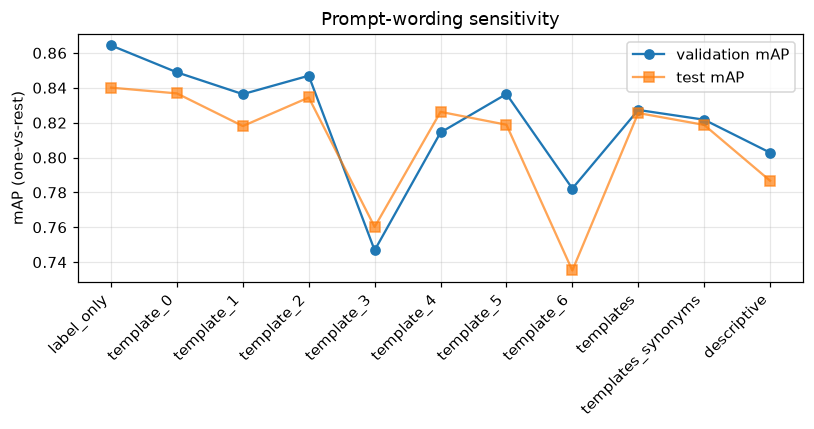

,condition,prompt,val_mAP,test_mAP,val_acc5,test_acc5
0,label_only,motorbike,0.8643,0.8401,0.5900,0.6236
1,template_0,a photo of a motorbike,0.8489,0.8368,0.6616,0.7155
2,template_1,a photograph of a motorbike,0.8364,0.8181,0.6312,0.6905
3,template_2,a picture of a motorbike,0.8469,0.8344,0.6508,0.6946
4,template_3,a close-up photo of a motorbike,0.7468,0.7602,0.6356,0.6934
5,template_4,a cropped photo of a motorbike,0.8144,0.8262,0.6768,0.7405
6,template_5,a photo of the motorbike,0.8364,0.8188,0.6182,0.6556
7,template_6,a photo of a motorbike in the wild,0.7822,0.7352,0.6659,0.7196
8,templates,7 averaged prompts,0.8273,0.8255,0.6529,0.7051
9,templates_synonyms,14 averaged prompts,0.8217,0.8187,0.6638,0.7109


In [16]:
sensitivity = []
conditions = {"label_only": {cat: [cat] for cat in CATEGORIES}}
for i, template in enumerate(TEMPLATES):
    conditions[f"template_{i}"] = {cat: [template.format(cat)] for cat in CATEGORIES}
conditions["templates"] = PROMPT_SETS["templates"]
conditions["templates_synonyms"] = PROMPT_SETS["templates_synonyms"]
conditions["descriptive"] = PROMPT_SETS["descriptive"]

for name, prompt_map in conditions.items():
    bank, _ = build_bank(prompt_map)
    vm, _ = evaluate_bank(bank, X_val, y_val)
    tm, _ = evaluate_bank(bank, test_l2, test_categories)
    sensitivity.append(dict(
        condition=name,
        prompt=(prompt_map["motorbike"][0] if len(prompt_map["motorbike"]) == 1
                else f"{len(prompt_map['motorbike'])} averaged prompts"),
        val_mAP=vm["mAP"], test_mAP=tm["mAP"],
        val_acc5=vm["acc5"], test_acc5=tm["acc5"],
        **{f"val_AP_{c}": vm[f"AP_{c}"] for c in CATEGORIES},
        **{f"test_AP_{c}": tm[f"AP_{c}"] for c in CATEGORIES},
    ))

sens_df = pd.DataFrame(sensitivity)
save_results(sens_df, RESULTS_DIR / "part4e_prompt_sensitivity.csv")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(range(len(sens_df)), sens_df.val_mAP, marker="o", label="validation mAP")
ax.plot(range(len(sens_df)), sens_df.test_mAP, marker="s", alpha=0.7, label="test mAP")
ax.set_xticks(range(len(sens_df)), sens_df.condition, rotation=45, ha="right")
ax.set_ylabel("mAP (one-vs-rest)")
ax.set_title("Prompt-wording sensitivity")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
display(sens_df[["condition", "prompt", "val_mAP", "test_mAP", "val_acc5", "test_acc5"]]
        .round(4).reset_index(drop=True))

## E.5 — Confusion matrices for the selected bank

The 5-way matrix isolates object classes; the 6-way matrix exposes what CLIP
does with background images when a background prompt is available.

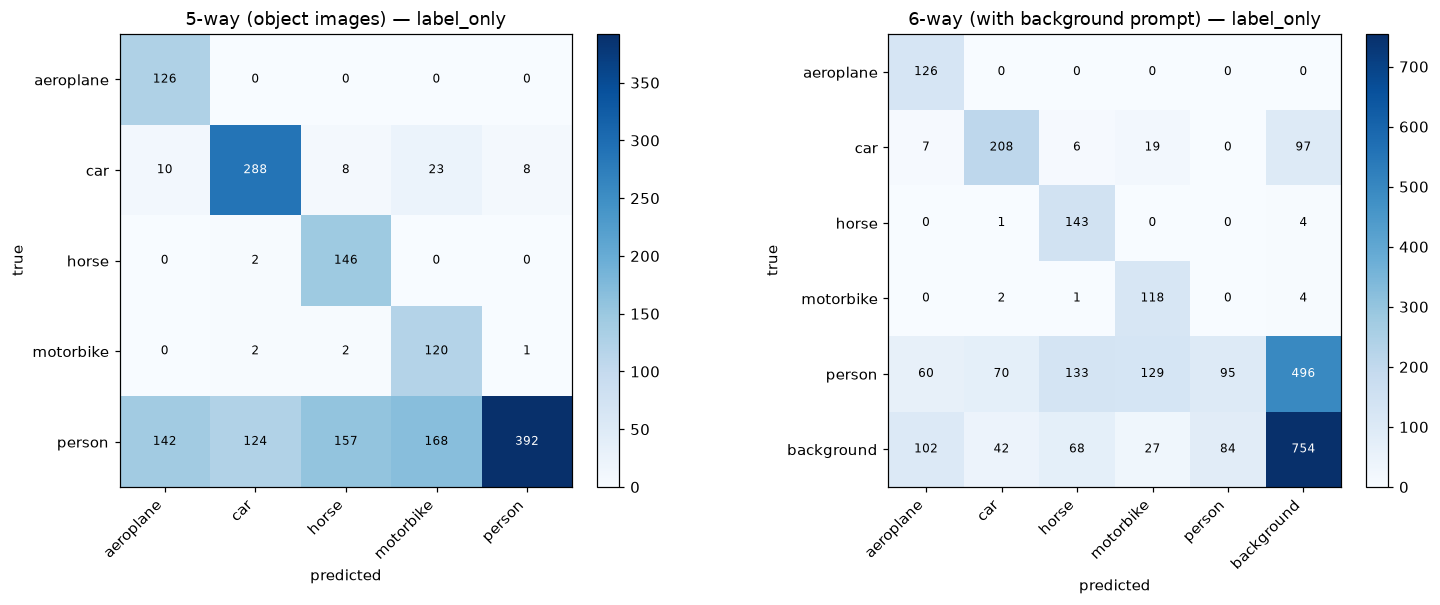

5-way accuracy=0.6236  6-way accuracy=0.5165


In [17]:
def plot_confusion(cm, labels, title, ax):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


obj = np.isin(test_categories, CATEGORIES)
y5 = test_categories[obj]
pred5 = np.asarray(CATEGORIES)[selected_scores[obj][:, :5].argmax(axis=1)]
cm5 = confusion_matrix(y5, pred5, labels=list(CATEGORIES))

labels6 = list(CATEGORIES) + [BACKGROUND]
pred6 = np.asarray(labels6)[selected_scores.argmax(axis=1)]
cm6 = confusion_matrix(test_categories, pred6, labels=labels6)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
plot_confusion(cm5, list(CATEGORIES), f"5-way (object images) — {BEST_PROMPT_SET}", axes[0])
plot_confusion(cm6, labels6, f"6-way (with background prompt) — {BEST_PROMPT_SET}", axes[1])
plt.tight_layout()
plt.show()

cm6_df = pd.DataFrame(cm6, index=labels6, columns=labels6)
save_results(cm6_df.reset_index(names="true"), RESULTS_DIR / "part4e_confusion_6way.csv")
print(f"5-way accuracy={accuracy_score(y5, pred5):.4f}  "
      f"6-way accuracy={accuracy_score(test_categories, pred6):.4f}")

## E.6 — CLIP image embeddings + linear SVM

The same frozen CLIP image descriptors, but with the supervised head used in
Stages A/B. This is the controlled comparison for the question “zero-shot vs a
linear SVM on frozen CLIP features”: identical inputs, different supervision.

In [18]:
summaries = []
for cat in CATEGORIES:
    X_tr, y_tr, n_tr = binary_subset(cat, train_l2, train_names, train_categories)
    X_te, y_te, _ = binary_subset(cat, test_l2, test_names, test_categories)
    summary, sweep, _ = evaluate_binary(
        cat, X_tr, y_tr, n_tr, X_te, y_te, val_names,
        C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
    )
    summaries.append(summary)
    flag = "" if summary["converged"] else "  [not converged]"
    print(f"{cat:<10s} C={summary['C']:<6g} val AP={summary['val_ap']:.4f}  "
          f"test AP={summary['test_ap']:.4f}{flag}")

clip_svm = pd.DataFrame(summaries)
clip_svm_map = float(clip_svm.test_ap.mean())
print(f"\nCLIP + SVM mAP: {clip_svm_map:.4f}")
save_results(clip_svm, RESULTS_DIR / "part4e_clip_svm_per_class.csv")

mc, mc_sweep, mc_per_class = evaluate_multiclass(
    train_l2, train_categories, train_names,
    test_l2, test_categories, val_names,
    C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
)
print(f"CLIP + SVM 6-way: C={mc['C']:g}  accuracy={mc['accuracy']:.4f}  "
      f"macro-F1={mc['macro_f1']:.4f}")
save_results(mc_per_class, RESULTS_DIR / "part4e_clip_svm_multiclass_per_class.csv")
display(clip_svm[["category", "dim", "n_pos_train", "C", "val_ap", "test_ap"]]
        .round(4).reset_index(drop=True))

aeroplane  C=0.1    val AP=1.0000  test AP=0.9961
car        C=1      val AP=0.9932  test AP=0.9869
horse      C=1      val AP=1.0000  test AP=0.9890
motorbike  C=1      val AP=0.9988  test AP=0.9933
person     C=1      val AP=0.9944  test AP=0.9929

CLIP + SVM mAP: 0.9917
CLIP + SVM 6-way: C=1  accuracy=0.8444  macro-F1=0.7733


,category,dim,n_pos_train,C,val_ap,test_ap
0,aeroplane,512,112,0.1,1.0000,0.9961
1,car,512,376,1.0,0.9932,0.9869
2,horse,512,139,1.0,1.0000,0.9890
3,motorbike,512,120,1.0,0.9988,0.9933
4,person,512,1025,1.0,0.9944,0.9929


## E.7 — Consolidated Part 4 comparison

`mAP` is the mean of the five one-vs-rest test APs. CLIP zero-shot uses the
validation-selected prompt bank; CLIP+SVM uses the same CLIP image embeddings
with a supervised head.

In [19]:
summary_rows = []

# Stage A / B tables, if they exist
for label, path in [
    ("ResNet-18 GAP + SVM", RESULTS_DIR / "part4a_resnet18_gap896_per_class.csv"),
    ("DINOv2 CLS + SVM", RESULTS_DIR / "part4b_dinov2_vits14_cls_per_class.csv"),
]:
    if path.exists():
        df = pd.read_csv(path)
        summary_rows.append(dict(
            representation=label,
            dim=int(df.dim.iloc[0]) if "dim" in df else np.nan,
            supervision="linear SVM",
            mAP=float(df.test_ap.mean()),
            AP_motorbike=float(df.loc[df.category == "motorbike", "test_ap"].iloc[0]),
        ))
    elif label.startswith("DINOv2"):
        # Stage B notebook may not have been run yet; use its feature cache.
        print("Stage B table missing; recomputing DINOv2 from its cache.")
        dino_train, _, _ = load_feature_cache(
            "dinov2_vits14", "train", "features_cls", target_names=train_names)
        dino_test, _, _ = load_feature_cache(
            "dinov2_vits14", "val", "features_cls", target_names=test_names)
        dino_train, dino_test = l2norm(dino_train), l2norm(dino_test)
        rows = []
        for cat in CATEGORIES:
            X_tr, y_tr, n_tr = binary_subset(
                cat, dino_train, train_names, train_categories)
            X_te, y_te, _ = binary_subset(
                cat, dino_test, test_names, test_categories)
            summary, _, _ = evaluate_binary(
                cat, X_tr, y_tr, n_tr, X_te, y_te, val_names,
                C_grid=DEFAULT_C_GRID, max_iter=MAX_ITER, seed=SEED,
            )
            rows.append(summary)
        df = pd.DataFrame(rows)
        summary_rows.append(dict(
            representation=label, dim=int(df.dim.iloc[0]),
            supervision="linear SVM", mAP=float(df.test_ap.mean()),
            AP_motorbike=float(df.loc[df.category == "motorbike", "test_ap"].iloc[0]),
        ))
    else:
        print("missing (run the earlier stage):", path)

summary_rows.append(dict(
    representation=f"CLIP ViT-B/32 zero-shot ({BEST_PROMPT_SET})",
    dim=512, supervision="none",
    mAP=float(selected_test["mAP"]),
    AP_motorbike=float(selected_test["AP_motorbike"]),
))
summary_rows.append(dict(
    representation="CLIP ViT-B/32 + SVM",
    dim=512, supervision="linear SVM",
    mAP=float(clip_svm_map),
    AP_motorbike=float(clip_svm.loc[clip_svm.category == "motorbike", "test_ap"].iloc[0]),
))

comparison = pd.DataFrame(summary_rows).sort_values("mAP", ascending=False)
save_results(comparison, RESULTS_DIR / "part4e_part4_summary.csv")
display(comparison.round(4).reset_index(drop=True))

,representation,dim,supervision,mAP,AP_motorbike
0,CLIP ViT-B/32 + SVM,512,linear SVM,0.9917,0.9933
1,DINOv2 CLS + SVM,384,linear SVM,0.9873,0.9818
2,ResNet-18 GAP + SVM,896,linear SVM,0.9697,0.9809
3,CLIP ViT-B/32 zero-shot (label_only),512,none,0.8401,0.9434
